імпотрування бібліотек

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

завантаження даних

In [41]:
data = pd.read_csv('Student Depression Dataset.csv')

кількість рядків та колонок в наборі даних

In [42]:
data.shape

(27901, 18)

назви всіх колонок, їх типи (dtype) та короткий опис 

In [43]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  str    
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  str    
 4   Profession                             27901 non-null  str    
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  str    
 11  Dietary Habit

кількість відсутніх значень (NA, NaN, null і тд) по кожному зі стовпців набору

In [44]:
data.isna().sum()

id                                       0
Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         3
Family History of Mental Illness         0
Depression                               0
dtype: int64

Короткий опис ознак набору даних (надано вручну)
id — унікальний ідентифікатор студента (штучний індекс, не несе аналітичного навантаження)
Gender — стать респондента (Категоріальна ознака: Male / Female)
Age — вік студента у роках (Числова ознака)
Citу — місто проживання або навчання (Категоріальна ознака)
Profession — рід занять (у межах цього датасету всі записи відповідають значенню Student)
Work Pressure — рівень робочого тиску (Числова/Рангова ознака; для студентів, які не працюють, дорівнює 0)
CGPA — середній бал успішності студента (Числова безперервна ознака)
Study Satisfaction — рівень задоволеності процесом навчання (Числова/Рангова ознака від 0 до 5)
Job Satisfaction — рівень задоволеності роботою (Числова/Рангова ознака; для безробітних студентів дорівнює 0)
Sleep Duration — тривалість сну на добу (Категоріальна/Інтервальна ознака)
Dietary Habits — характер та якість харчування (Категоріальна ознака: Healthy / Moderate / Unhealthy)
Degree — освітній ступінь або спеціалізація, за якою навчається студент (Категоріальна ознака)
Have you ever had suicidal thoughts ? — наявність суїцидальних думок в анамнезі (Бінарна ознака: Yes / No)
Work/Study Hours — кількість годин, що витрачаються на навчання чи роботу щодня (Числова ознака)
Financial Stress — рівень стресу, пов'язаний із фінансовим становищем (Числова/Рангова ознака від 0 до 5)
Family History of Mental Illness — наявність психічних захворювань у сімейному анамнезі (Бінарна ознака: Yes / No)
Depression — наявність діагностованої депресії (Цільова бінарна ознака: 1 — так, 0 — ні)

In [45]:
median_fin_stress = data['Financial Stress'].median()
data['Financial Stress'] = data['Financial Stress'].fillna(median_fin_stress)

In [46]:
data.isna().sum()

id                                       0
Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         0
Family History of Mental Illness         0
Depression                               0
dtype: int64

In [47]:
num_cols = data.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = data.select_dtypes(include=['object', 'string']).columns.tolist()
print(f"Числові стовпці: {num_cols}")
print(f"Категоріальні стовпці: {cat_cols}")
print(f"Часові стовпці: Відсутні (але є тривалість сну та роботи)")

Числові стовпці: ['id', 'Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours', 'Financial Stress', 'Depression']
Категоріальні стовпці: ['Gender', 'City', 'Profession', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']
Часові стовпці: Відсутні (але є тривалість сну та роботи)


статистикa для числових колонок та розподіл для категоріальних

In [48]:
print(" Статистика числових ознак")
display(data[['Age', 'CGPA', 'Work/Study Hours', 'Financial Stress']].describe())

 Статистика числових ознак


,Age,CGPA,Work/Study Hours,Financial Stress
count,27901.000000,27901.000000,27901.000000,27901.000000
mean,25.822300,7.656104,7.156984,3.139852
std,4.905687,1.470707,3.707642,1.437270
min,18.000000,0.000000,0.000000,1.000000
25%,21.000000,6.290000,4.000000,2.000000
50%,25.000000,7.770000,8.000000,3.000000
75%,30.000000,8.920000,10.000000,4.000000
max,59.000000,10.000000,12.000000,5.000000


In [49]:
print(" Розподіл категоріальної ознаки 'Sleep Duration'")
print(data['Sleep Duration'].value_counts(dropna=False))

 Розподіл категоріальної ознаки 'Sleep Duration'
Sleep Duration
Less than 5 hours    8310
7-8 hours            7346
5-6 hours            6183
More than 8 hours    6044
Others                 18
Name: count, dtype: int64


таблиця з абсолютними та відносними значеннями

In [50]:
for col in cat_cols:
    print(f"Аналіз розподілу для ознаки: {col} ")
    
    counts = data[col].value_counts()
    percentages = data[col].value_counts(normalize=True) * 100
    
    distribution_df = pd.DataFrame({
        'Кількість (абс.)': counts,
        'Частка (%)': percentages.round(2)
    })
    
    print(distribution_df)
    print("" + "="*50 + "")

Аналіз розподілу для ознаки: Gender 
        Кількість (абс.)  Частка (%)
Gender                              
Male               15547       55.72
Female             12354       44.28
Аналіз розподілу для ознаки: City 
                    Кількість (абс.)  Частка (%)
City                                            
Kalyan                          1570        5.63
Srinagar                        1372        4.92
Hyderabad                       1340        4.80
Vasai-Virar                     1290        4.62
Lucknow                         1155        4.14
Thane                           1139        4.08
Ludhiana                        1111        3.98
Agra                            1094        3.92
Surat                           1078        3.86
Kolkata                         1066        3.82
Jaipur                          1036        3.71
Patna                           1007        3.61
Visakhapatnam                    969        3.47
Pune                             968        3

In [51]:
print(" Розподіл цільової змінної 'Depression'")
print(data['Depression'].value_counts(normalize=True) * 100) 

 Розподіл цільової змінної 'Depression'
Depression
1    58.549873
0    41.450127
Name: proportion, dtype: float64


переіменування колонок

In [52]:
data = data.rename(columns={
    'Have you ever had suicidal thoughts ?': 'Suicidal_Thoughts',
    'Family History of Mental Illness': 'Family_History',
    'Academic Pressure': 'Academic_Pressure',
    'Work Pressure': 'Work_Pressure',
    'Study Satisfaction': 'Study_Satisfaction',
    'Job Satisfaction': 'Job_Satisfaction',
    'Sleep Duration': 'Sleep_Duration',
    'Dietary Habits': 'Dietary_Habits',
    'Work/Study Hours': 'Work_Study_Hours',
    'Financial Stress': 'Financial_Stress'
})

In [53]:
data.sample(10)

,id,Gender,Age,City,Profession,Academic_Pressure,Work_Pressure,CGPA,Study_Satisfaction,Job_Satisfaction,Sleep_Duration,Dietary_Habits,Degree,Suicidal_Thoughts,Work_Study_Hours,Financial_Stress,Family_History,Depression
18783,95070,Female,31.0,Visakhapatnam,Student,4.0,0.0,9.37,1.0,0.0,7-8 hours,Healthy,BA,Yes,12.0,3.0,No,1
2032,10424,Male,32.0,Ghaziabad,Student,2.0,0.0,9.91,1.0,0.0,7-8 hours,Unhealthy,BHM,No,12.0,5.0,No,0
1464,7556,Male,26.0,Jaipur,Student,5.0,0.0,9.56,5.0,0.0,Less than 5 hours,Unhealthy,B.Ed,Yes,11.0,2.0,Yes,1
18460,93463,Male,33.0,Agra,Student,2.0,0.0,9.31,3.0,0.0,Less than 5 hours,Healthy,M.Tech,Yes,7.0,5.0,No,0
26135,131798,Male,27.0,Hyderabad,Student,3.0,0.0,9.21,3.0,0.0,7-8 hours,Moderate,M.Ed,Yes,7.0,4.0,Yes,1
6395,32037,Male,34.0,Vasai-Virar,Student,1.0,0.0,8.58,3.0,0.0,7-8 hours,Moderate,B.Ed,No,0.0,3.0,No,0
394,1969,Female,24.0,Kolkata,Student,5.0,0.0,7.28,1.0,0.0,Less than 5 hours,Unhealthy,B.Com,Yes,2.0,4.0,No,1
4763,23886,Male,33.0,Mumbai,Student,2.0,0.0,7.02,4.0,0.0,More than 8 hours,Unhealthy,B.Tech,No,0.0,5.0,No,0
10106,51115,Male,24.0,Srinagar,Student,2.0,0.0,6.10,1.0,0.0,7-8 hours,Moderate,B.Com,Yes,9.0,4.0,No,1
329,1605,Female,27.0,Delhi,Student,3.0,0.0,9.05,1.0,0.0,7-8 hours,Healthy,LLB,Yes,2.0,5.0,No,1


видалення непотрібної колонки

In [54]:
data = data.drop(columns=['id', 'Job_Satisfaction', 'Work_Pressure'])

переводимо yes/no у 1/0

In [55]:
binary_map = {'Yes': 1, 'No': 0}
data['Suicidal_Thoughts'] = data['Suicidal_Thoughts'].map(binary_map)
data['Family_History'] = data['Family_History'].map(binary_map)

загальний рівень стресу

In [56]:
data['Total_Pressure'] = (
    data['Academic_Pressure'].fillna(0) +  
    data['Financial_Stress'].fillna(0)
)

групуємо вік 

In [57]:
bins = [0, 20, 25, 30, 40, 100]
labels = ['<20', '21-25', '26-30', '31-40', '40+']
data['Age_Group'] = pd.cut(data['Age'], bins=bins, labels=labels)

перевірка

In [58]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Gender              27901 non-null  str     
 1   Age                 27901 non-null  float64 
 2   City                27901 non-null  str     
 3   Profession          27901 non-null  str     
 4   Academic_Pressure   27901 non-null  float64 
 5   CGPA                27901 non-null  float64 
 6   Study_Satisfaction  27901 non-null  float64 
 7   Sleep_Duration      27901 non-null  str     
 8   Dietary_Habits      27901 non-null  str     
 9   Degree              27901 non-null  str     
 10  Suicidal_Thoughts   27901 non-null  int64   
 11  Work_Study_Hours    27901 non-null  float64 
 12  Financial_Stress    27901 non-null  float64 
 13  Family_History      27901 non-null  int64   
 14  Depression          27901 non-null  int64   
 15  Total_Pressure      27901 non-null  float64 
 1

візуалізаціія

вік студентів

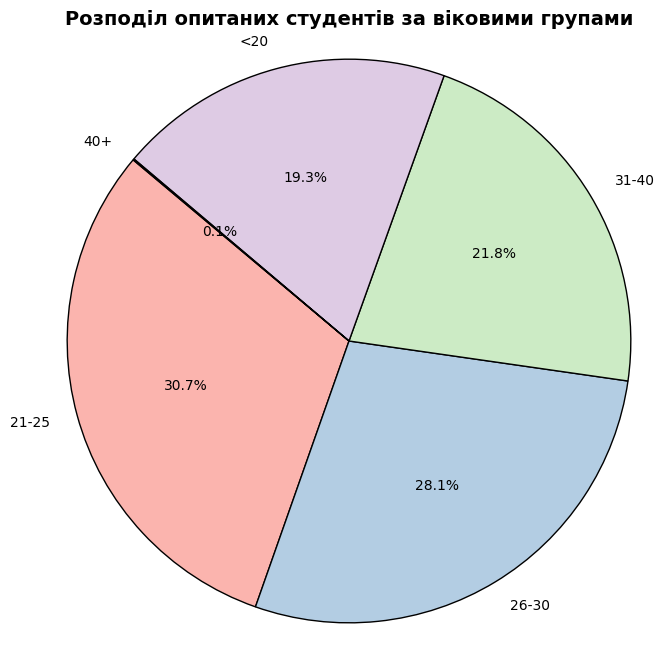

In [59]:
age_group_counts = data['Age_Group'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(
    age_group_counts, 
    labels=age_group_counts.index, 
    autopct='%1.1f%%', 
    startangle=140,  
    colors=plt.cm.Pastel1.colors, 
    wedgeprops={'edgecolor': 'black'} )

plt.title('Розподіл опитаних студентів за віковими групами', fontsize=14, fontweight='bold')
plt.axis('equal') 
plt.show()

Тип графіка: Кругова діаграма (pie chart)
Обґрунтування: Підходить для відображення часток цілого. Вікових категорій небагато (5), тому діаграма не перевантажена і легко читається — одразу видно домінуючу групу.
Спостереження: Домінує вікова група 21–25 років (30.7%), що відповідає типовій студентській аудиторії. Частка 40+ є мінімальною, що підтверджує молодіжний характер вибірки.

розподіл за тривалістю сну

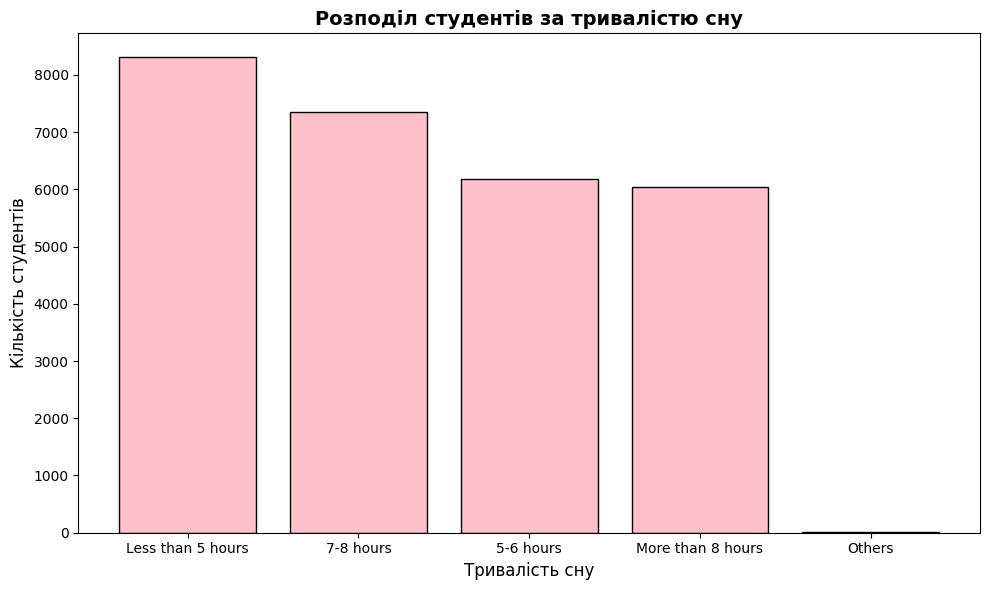

In [60]:
sleep_counts = data['Sleep_Duration'].value_counts()
plt.figure(figsize=(10, 6))
bars = plt.bar(sleep_counts.index, sleep_counts.values, color='pink', edgecolor='black')
plt.title('Розподіл студентів за тривалістю сну', fontsize=14, fontweight='bold')
plt.xlabel('Тривалість сну', fontsize=12)
plt.ylabel('Кількість студентів', fontsize=12)
plt.tight_layout()
plt.show()

Тип графіка: Bar chart
Обґрунтування: Найкращий варіант для порівняння абсолютних значень між категоріями. Дозволяє одразу побачити, яка тривалість сну є найпоширенішою.
Спостереження: Найбільше студентів спить менше 5 годин — це тривожний показник, що свідчить про суттєве навантаження. Категорія 'більше 8 годин' 'інше' є найменш поширеними.

рівень фінансового стресу залежно від наявності депресії

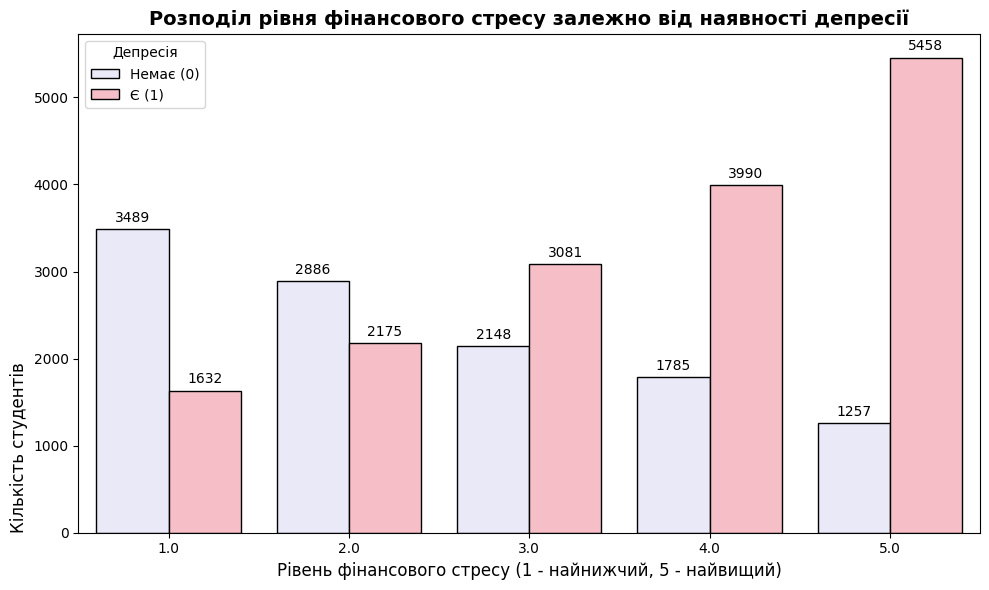

In [61]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=data, 
    x='Financial_Stress', 
    hue='Depression', 
    palette=['#E6E6FA', '#FFB6C1'], 
    edgecolor='black')
ax.set_ylim(bottom=0)
plt.margins(y=0)
plt.xlabel('Рівень фінансового стресу (1 - найнижчий, 5 - найвищий)', fontsize=12)
plt.ylabel('Кількість студентів', fontsize=12, loc='bottom')
plt.title('Розподіл рівня фінансового стресу залежно від наявності депресії', fontsize=14, fontweight='bold')
plt.legend(title='Депресія', labels=['Немає (0)', 'Є (1)'])
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)
plt.tight_layout()
plt.show()

Тип графіка: Grouped countplot
Обґрунтування: Дозволяє одночасно порівняти розподіл двох змінних — рівня фінансового стресу та наявності депресії. Ефективніший за два окремі графіки, оскільки чітко демонструє залежність.
Спостереження: Прослідковується чіткий тренд: зі зростанням фінансового стресу частка студентів з депресією лінійно збільшується. При рівні 1 переважають здорові студенти, при рівні 5 — навпаки.

вплив академічного тиску на середній бал

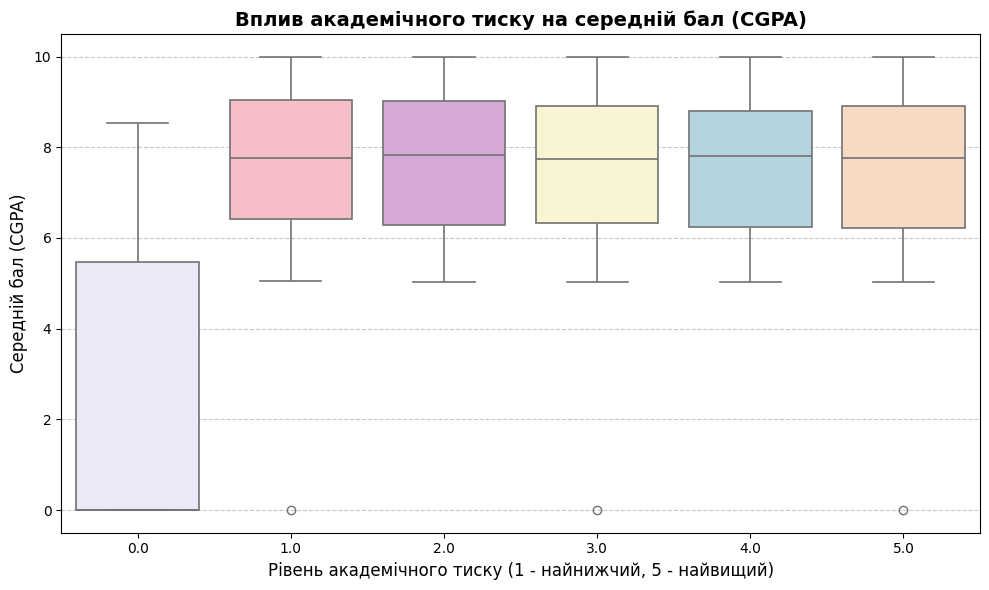

In [62]:
my_colors = ['#E6E6FA', '#FFB6C1', '#DDA0DD', '#FFFACD', '#ADD8E6', '#FFDAB9']
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=data, 
    x='Academic_Pressure', 
    y='CGPA', 
    hue='Academic_Pressure', 
    palette=my_colors,      
    legend=False,           
    linewidth=1.2)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.title('Вплив академічного тиску на середній бал (CGPA)', fontsize=14, fontweight='bold')
plt.xlabel('Рівень академічного тиску (1 - найнижчий, 5 - найвищий)', fontsize=12)
plt.ylabel('Середній бал (CGPA)', fontsize=12)
plt.tight_layout()
plt.show()

Тип графіка: boxplot
Обґрунтування: Дозволяє відобразити медіану, розкид та викиди одночасно для кожної групи тиску. Ефективний для порівняння розподілів числової змінної між кількома категоріями.
Спостереження: Медіана CGPA стабільно тримається в діапазоні 6.5–9.5 для всіх рівнів тиску. Академічний тиск практично не впливає на успішність.

розподіл робочих/навчальних годин залежно від депресії

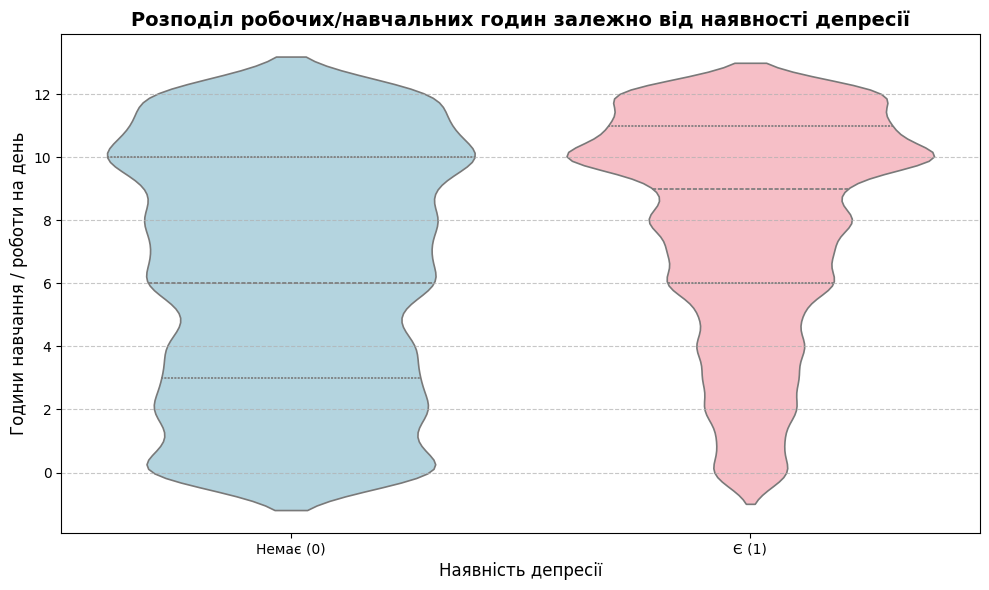

In [63]:
plt.figure(figsize=(10, 6))
my_colors = ['#ADD8E6', '#FFB6C1']
sns.violinplot(
    data=data, 
    x='Depression', 
    y='Work_Study_Hours', 
    hue='Depression',      
    palette=my_colors, 
    legend=False, 
    inner='quartile',     
    linewidth=1.2)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.title('Розподіл робочих/навчальних годин залежно від наявності депресії', fontsize=14, fontweight='bold')
plt.xlabel('Наявність депресії', fontsize=12)
plt.ylabel('Години навчання / роботи на день', fontsize=12)
plt.xticks([0, 1], ['Немає (0)', 'Є (1)'])
plt.tight_layout()
plt.show()

Тип графіка: Violin plot
Обґрунтування: Поєднує переваги boxplot і KDE — показує не лише медіану й розкид, а й форму розподілу. Ідеально підходить для порівняння двох груп (є/немає депресія).
Спостереження: Обидві групи мають схожий розподіл із піком близько 10 годин на день. Суттєвої різниці між студентами з депресією і без неї не виявлено — час навчання не є визначальним фактором.

зміна середнього рівня задоволеності навчанням за віком

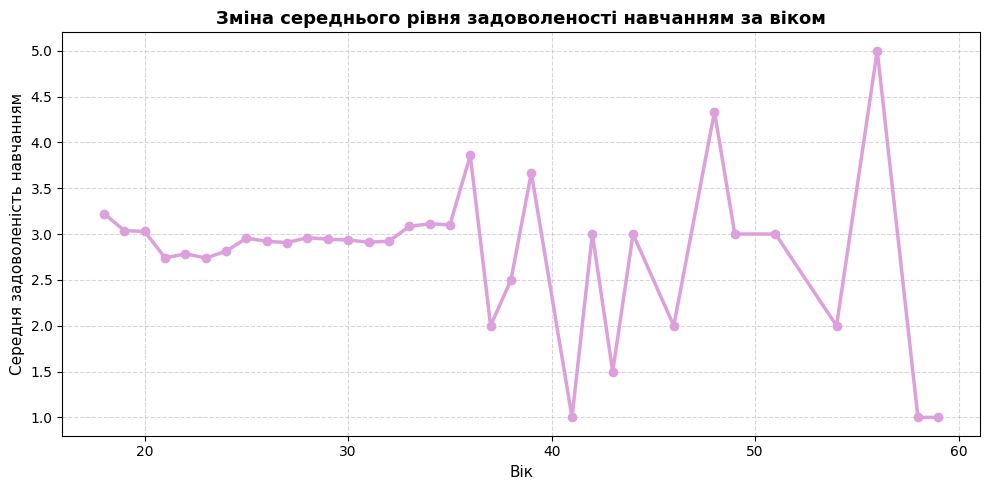

In [64]:
age_satisfaction = data.groupby('Age')['Study_Satisfaction'].mean()
plt.figure(figsize=(10, 5))
plt.plot(age_satisfaction.index, age_satisfaction.values, marker='o', color='#DDA0DD', linewidth=2.5)
plt.title('Зміна середнього рівня задоволеності навчанням за віком', fontsize=13, fontweight='bold')
plt.xlabel('Вік', fontsize=11)
plt.ylabel('Середня задоволеність навчанням', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Тип графіка: Line plot
Обґрунтування: Лінійний графік найкраще відображає динаміку неперервної змінної в часі або по континуальній шкалі (тут — по віку). Дозволяє бачити тренд.
Спостереження: До 35 років рівень задоволеності залишається відносно стабільним. Після 40 спостерігається помітне падіння — старші студенти значно менше задоволені навчальним процесом.

порівняння CGPA за депресією 

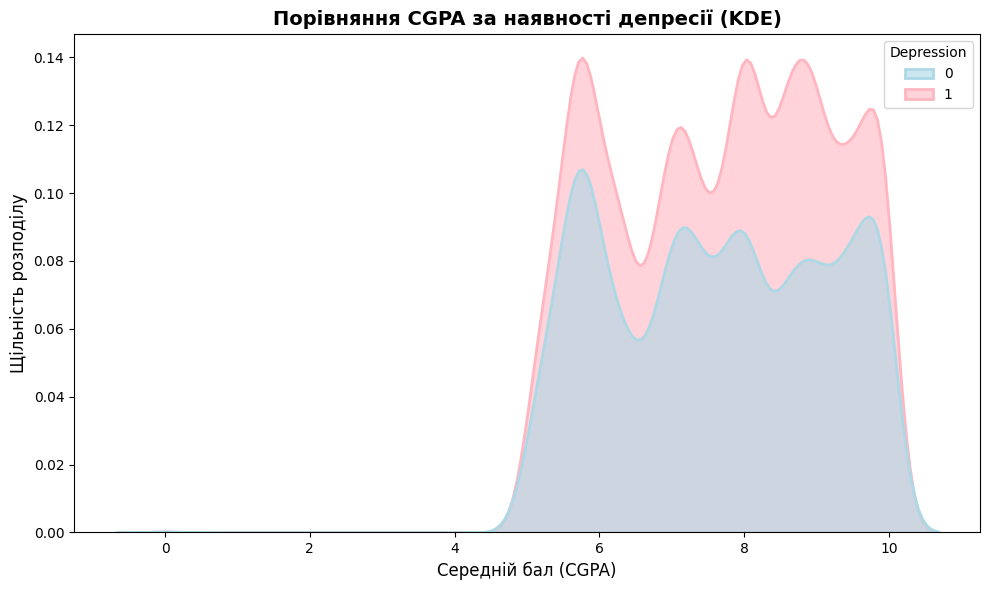

In [65]:
plt.figure(figsize=(10, 6))
my_colors = ['#ADD8E6', '#FFB6C1']
sns.kdeplot(
    data=data, 
    x='CGPA', 
    hue='Depression', 
    fill=True,           
    palette=my_colors, 
    alpha=0.6,           
    linewidth=2)
plt.title('Порівняння CGPA за наявності депресії (KDE)', fontsize=14, fontweight='bold')
plt.xlabel('Середній бал (CGPA)', fontsize=12)
plt.ylabel('Щільність розподілу', fontsize=12)
plt.tight_layout()
plt.show()

Тип графіка: KDE (Kernel Density Estimate)
Обґрунтування: Дозволяє порівняти форму розподілу CGPA між двома групами без прив'язки до конкретних бінів гістограми. Плавні криві полегшують зорове порівняння.
Спостереження: Криві розподілу CGPA для студентів з депресією та без неї майже повністю збігаються. Це підтверджує, що наявність депресії не впливає на академічну успішність.

взаємозв'язок між годинами навчання та оцінками 

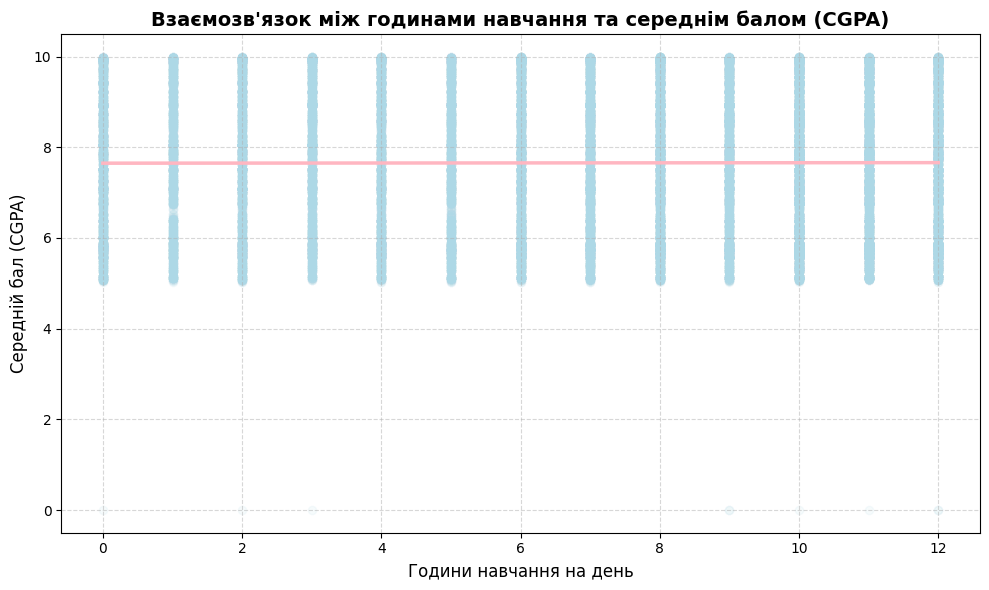

In [66]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=data,
    x='Work_Study_Hours',
    y='CGPA',
    scatter_kws={'color': '#ADD8E6', 'alpha': 0.1}, 
    line_kws={'color': '#FFB6C1', 'linewidth': 2.5} 
)

plt.title('Взаємозв\'язок між годинами навчання та середнім балом (CGPA)', fontsize=14, fontweight='bold')
plt.xlabel('Години навчання на день', fontsize=12)
plt.ylabel('Середній бал (CGPA)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Тип графіка: Scatter plot з лінією регресії
Обґрунтування: Регресійний графік дозволяє одночасно побачити розсіяння точок і загальний тренд лінії. Ідеальний для перевірки гіпотези про лінійну залежність між двома числовими змінними.
Спостереження: Лінія регресії майже горизонтальна — залежності між кількістю годин навчання та CGPA не виявлено. Оцінки щільно згруповані у діапазоні 6.5–9.5 незалежно від навантаження.

Топ-10 міст за кількістю студентів

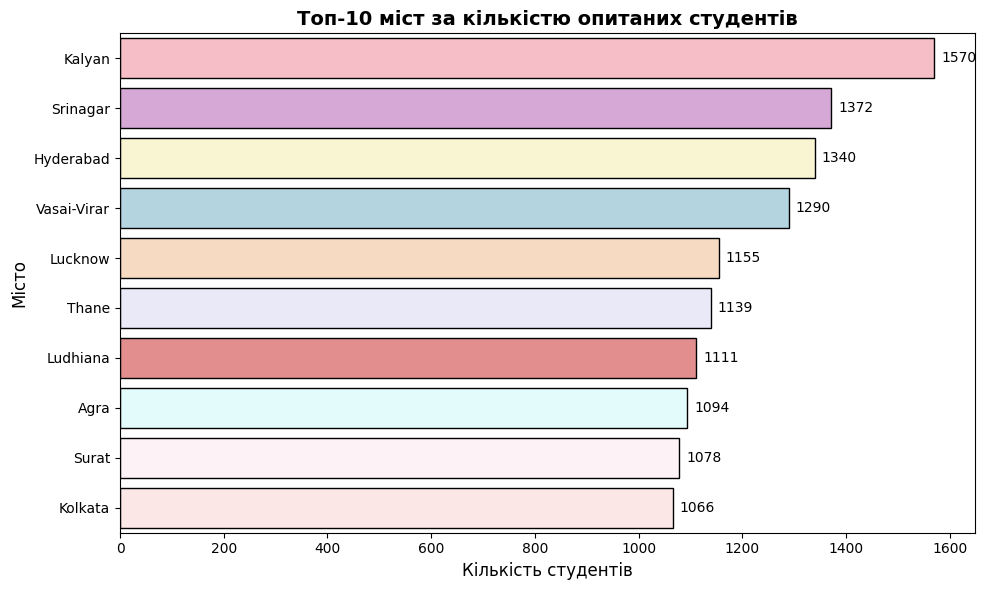

In [67]:
top_cities = data['City'].value_counts().head(10)
plt.figure(figsize=(10, 6))
my_colors = ['#FFB6C1', '#DDA0DD', '#FFFACD', '#ADD8E6', '#FFDAB9', '#E6E6FA', '#F08080', '#E0FFFF', '#FFF0F5', '#FFE4E1']
ax = sns.barplot(
    x=top_cities.values, 
    y=top_cities.index, 
    hue=top_cities.index, 
    palette=my_colors,
    legend=False,
    edgecolor='black')
ax.set_xlim(left=0)
plt.margins(x=0)
plt.xlabel('Кількість студентів', fontsize=12)
plt.ylabel('Місто', fontsize=12)
plt.title('Топ-10 міст за кількістю опитаних студентів', fontsize=14, fontweight='bold')
for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=10)
plt.tight_layout()
plt.show()

Тип графіка: Горизонтальний barplot
Обґрунтування: Горизонтальне розташування зручніше для категорій з довгими назвами (міста). Дозволяє швидко порівняти популярність локацій без перекриття підписів.
Спостереження: Лідери — Kalyan та Srinagar. Kolkata представлено найменше. Географічний розподіл нерівномірний, що може впливати на репрезентативність вибірки.

зв'язок між наявністю психічних захворювань у родині та суїцидальними думками

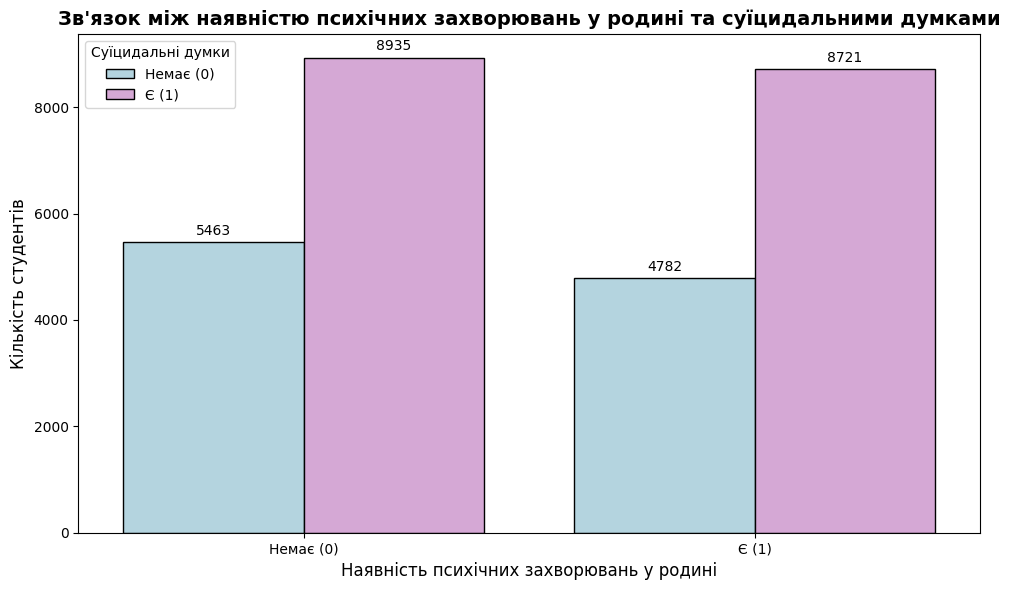

In [68]:
plt.figure(figsize=(10, 6))
my_colors = ['#ADD8E6', '#DDA0DD']
ax = sns.countplot(
    data=data, 
    x='Family_History', 
    hue='Suicidal_Thoughts', 
    palette=my_colors,
    edgecolor='black')
ax.set_ylim(bottom=0)
plt.margins(y=0)
plt.title('Зв\'язок між наявністю психічних захворювань у родині та суїцидальними думками', fontsize=14, fontweight='bold')
plt.xlabel('Наявність психічних захворювань у родині', fontsize=12)
plt.ylabel('Кількість студентів', fontsize=12)
plt.xticks([0, 1], ['Немає (0)', 'Є (1)'])
plt.legend(title='Суїцидальні думки', labels=['Немає (0)', 'Є (1)'])
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)
plt.tight_layout()
plt.show()

Тип графіка: Grouped countplot
Обґрунтування: Дозволяє зіставити дві бінарні змінні — наявність психічних захворювань у родині та суїцидальні думки — і візуально оцінити, чи є між ними зв'язок.
Спостереження: Розподіл суїцидальних думок є майже однаковим в обох групах (із сімейною історією і без). Спадковість не є визначальним фактором у цьому датасеті.

наявність депресії

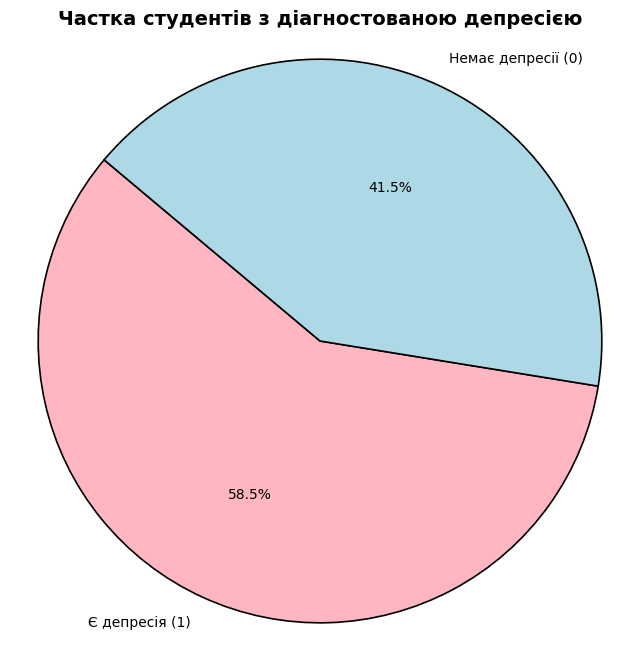

In [69]:
depression_counts = data['Depression'].value_counts()
plt.figure(figsize=(8, 8))
labels = ['Є депресія (1)', 'Немає депресії (0)']
my_colors = ['#FFB6C1', '#ADD8E6']
plt.pie(
    depression_counts, 
    labels=labels, 
    autopct='%1.1f%%',            
    startangle=140,               
    colors=my_colors,             
    wedgeprops={'edgecolor': 'black', 'linewidth': 1.2} )
plt.title('Частка студентів з діагностованою депресією', fontsize=14, fontweight='bold')
plt.axis('equal') 
plt.show()

Тип графіка: Pie chart
Обґрунтування: Для відображення простого співвідношення двох категорій кругова діаграма є найнаочнішою — одним поглядом бачимо пропорцію.
Спостереження: 58.5% студентів мають депресію — більшість вибірки. Це робить датасет дещо незбалансованим.

як розподіляється середній бал (CGPA) серед усіх студентів

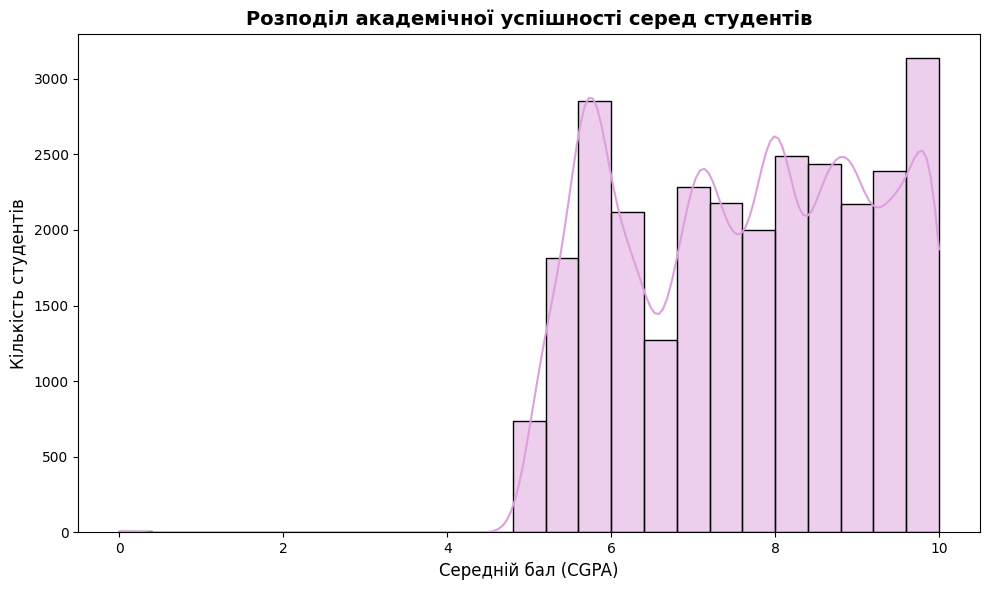

In [70]:
plt.figure(figsize=(10, 6))
ax = sns.histplot(
    data=data, 
    x='CGPA', 
    bins=25,              
    kde=True,              
    color='#DDA0DD', 
    edgecolor='black')
ax.set_ylim(bottom=0)
plt.margins(y=0)
plt.title('Розподіл академічної успішності серед студентів', fontsize=14, fontweight='bold')
plt.xlabel('Середній бал (CGPA)', fontsize=12)
plt.ylabel('Кількість студентів', fontsize=12)
plt.tight_layout()
plt.show()

Тип графіка: Гістограма з KDE
Обґрунтування: Поєднання гістограми і KDE дає повну картину: стовпці показують абсолютну кількість, а крива — загальну форму розподілу. Ефективно для числових ознак.
Спостереження: Розподіл CGPA є лівоасиметричним з концентрацією в діапазоні 9–10 балів. Більшість студентів є успішними — слабких студентів у вибірці мало.

залежність суїцидальних думок від академічного тиску

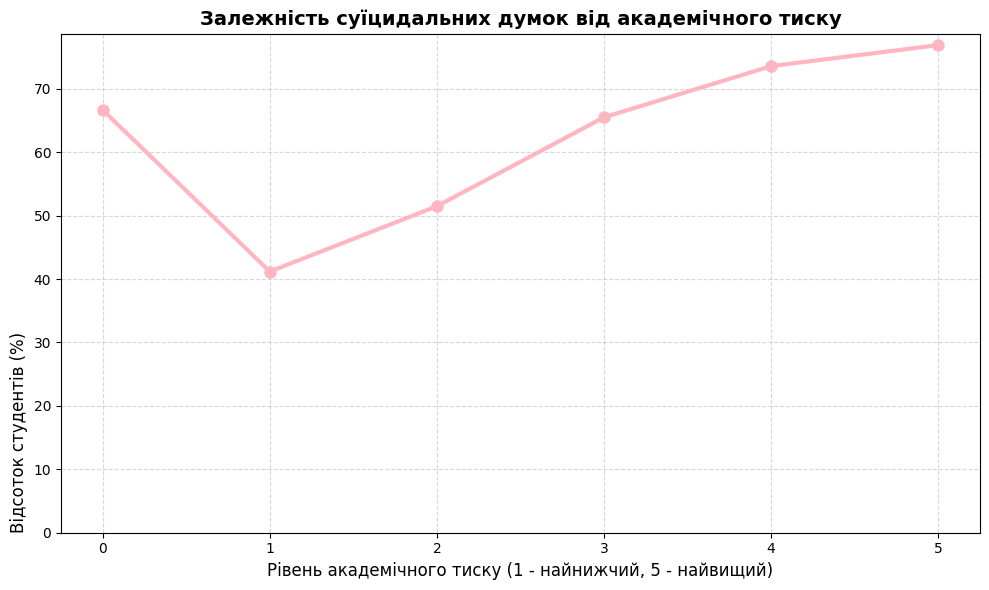

In [71]:
suicidal_percentage = data.groupby('Academic_Pressure')['Suicidal_Thoughts'].mean() * 100
plt.figure(figsize=(10, 6))
plt.plot(
    suicidal_percentage.index, 
    suicidal_percentage.values, 
    marker='o',          
    color='#FFB6C1',     
    linewidth=3,        
    markersize=8)
plt.ylim(bottom=0)
plt.title('Залежність суїцидальних думок від академічного тиску', fontsize=14, fontweight='bold')
plt.xlabel('Рівень академічного тиску (1 - найнижчий, 5 - найвищий)', fontsize=12)
plt.ylabel('Відсоток студентів (%)', fontsize=12, loc='bottom')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(suicidal_percentage.index)
plt.tight_layout()
plt.show()

Тип графіка: Line plot 
Обґрунтування: Лінійний графік чітко відображає тренд залежності між порядковою змінною (тиск) і бінарним результатом. Простіше читається, ніж barplot із відсотками.
Спостереження: Частка студентів із суїцидальними думками монотонно зростає зі збільшенням академічного тиску. При рівні 5 вона є максимальною — це один із найбільш тривожних трендів у даних.

успішність залежно від тривалості сну

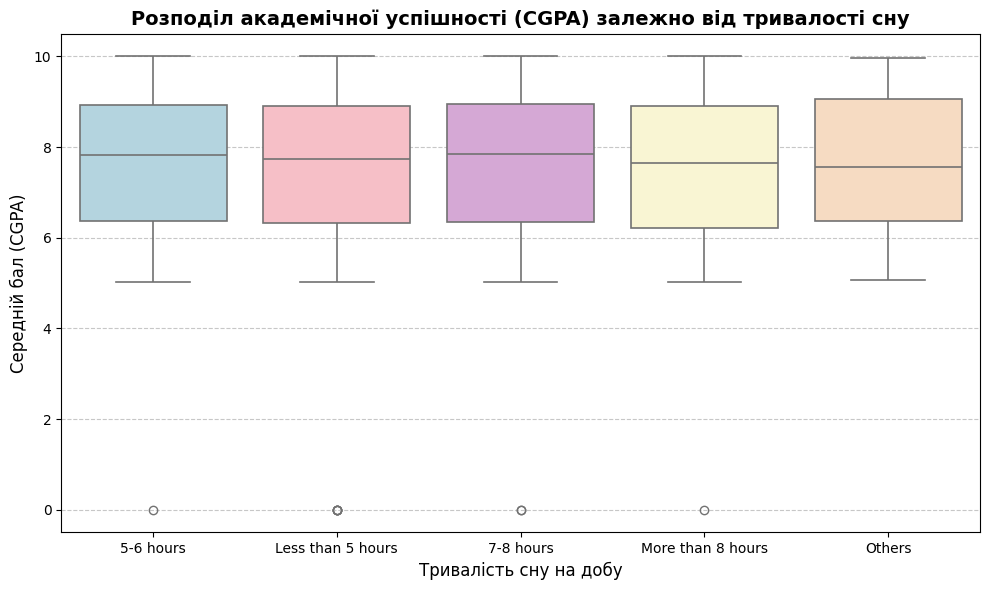

In [72]:
my_colors = ['#ADD8E6', '#FFB6C1', '#DDA0DD', '#FFFACD', '#FFDAB9']
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=data, 
    x='Sleep_Duration', 
    y='CGPA', 
    hue='Sleep_Duration', 
    palette=my_colors, 
    legend=False, 
    linewidth=1.2)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.title('Розподіл академічної успішності (CGPA) залежно від тривалості сну', fontsize=14, fontweight='bold')
plt.xlabel('Тривалість сну на добу', fontsize=12)
plt.ylabel('Середній бал (CGPA)', fontsize=12)
plt.tight_layout()
plt.show()

Тип графіка: Boxplot
Обґрунтування: Дозволяє порівняти розподіл CGPA для різних категорій тривалості сну одночасно, включно з медіаною та викидами.
Спостереження: Медіани CGPA для всіх груп тривалості сну є майже ідентичними. Тривалість сну не впливає на успішність — навіть студенти з хронічним недосипанням мають високі оцінки.

щільність академічного тиску

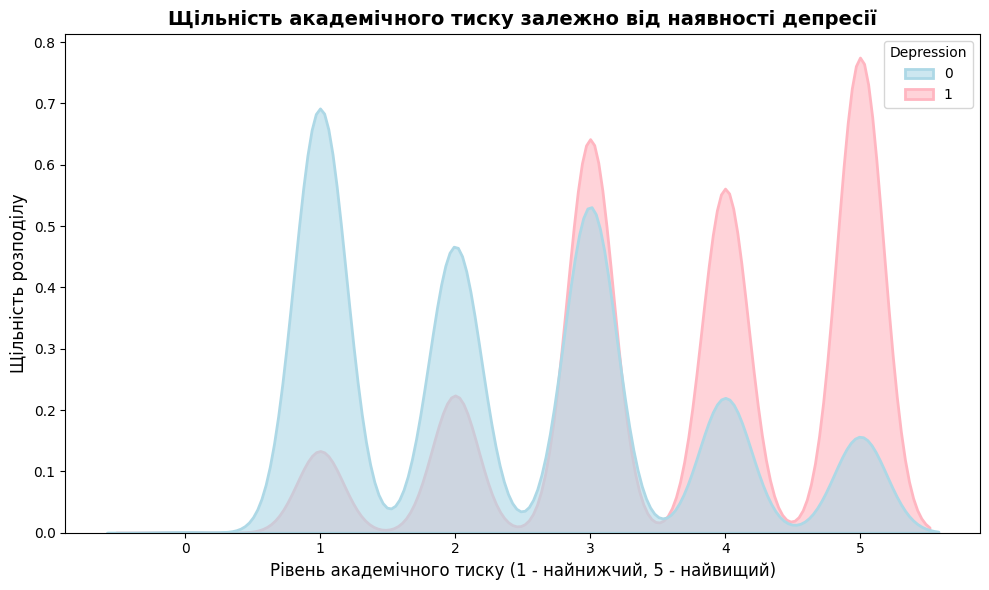

In [73]:
plt.figure(figsize=(10, 6))
my_colors = ['#ADD8E6', '#FFB6C1']
ax = sns.kdeplot(
    data=data, 
    x='Academic_Pressure', 
    hue='Depression', 
    fill=True,             
    palette=my_colors, 
    alpha=0.6,             
    linewidth=2,          
    common_norm=False)
ax.set_ylim(bottom=0)
plt.margins(y=0)
plt.title('Щільність академічного тиску залежно від наявності депресії', fontsize=14, fontweight='bold')
plt.xlabel('Рівень академічного тиску (1 - найнижчий, 5 - найвищий)', fontsize=12)
plt.ylabel('Щільність розподілу', fontsize=12)
plt.tight_layout()
plt.show()

Тип графіка: KDE 
Обґрунтування: Порівняння KDE для двох груп дозволяє побачити, де розподіл академічного тиску «зміщується» у бік депресії. Ефективніший за гістограму при порівнянні форм розподілів.
Спостереження: Студенти без депресії мають більш рівномірний розподіл тиску. Серед тих, хто має депресію, крива зміщена вправо — до вищих значень тиску. Зв'язок є, але не абсолютний.

взаємозв'язок між віком, середнім балом (CGPA) та депресією

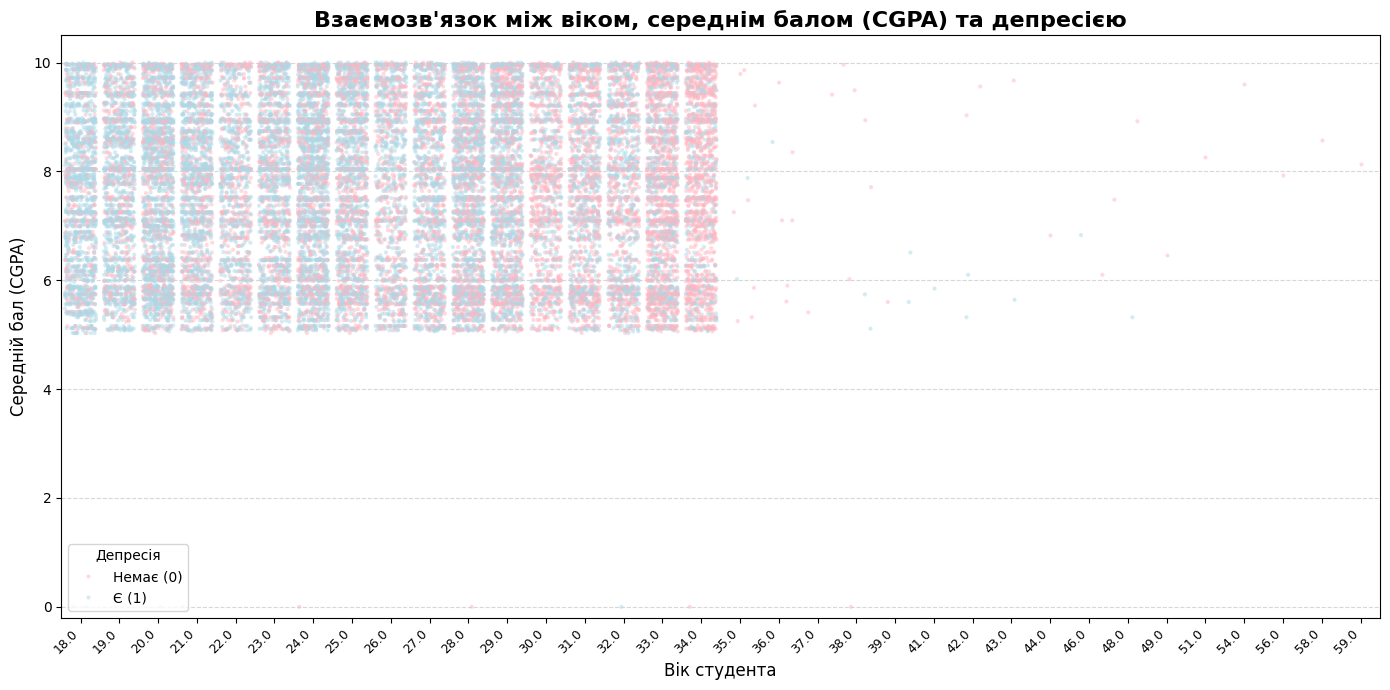

In [74]:
unique_ages = np.sort(data['Age'].unique())
if len(unique_ages) > 40:
  unique_ages = np.arange(int(data['Age'].min()), int(data['Age'].max()) + 1)
plt.figure(figsize=(14, 7))
my_colors = ['#FFB6C1', '#ADD8E6']
ax = sns.stripplot(
    data=data,
    x='Age',
    y='CGPA',
    hue='Depression',
    palette=my_colors,
    alpha=0.5,
    jitter=0.4,
    size=3,
    order=unique_ages)
ax.set_ylim(bottom=-0.2, top=10.5)
plt.margins(y=0)
plt.title("Взаємозв'язок між віком, середнім балом (CGPA) та депресією", fontsize=16, fontweight='bold')
plt.xlabel('Вік студента', fontsize=12)
plt.ylabel('Середній бал (CGPA)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=9) 
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles, ['Немає (0)', 'Є (1)'], title='Депресія', loc='lower left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Тип графіка: Strip plot
Обґрунтування: Дозволяє відобразити розподіл CGPA по кожному окремому значенню віку без агрегації. Jitter запобігає накладанню точок. Ефективно при великій кількості спостережень і необхідності побачити «сирі» дані.
Спостереження: У всіх вікових групах точки обох кольорів (є/немає депресія) рівномірно перемішані по всьому діапазону CGPA. Ні вік, ні депресія не формують окремих кластерів — успішність є незалежною від обох факторів.

частка студентів з депресією залежно від харчових звичок

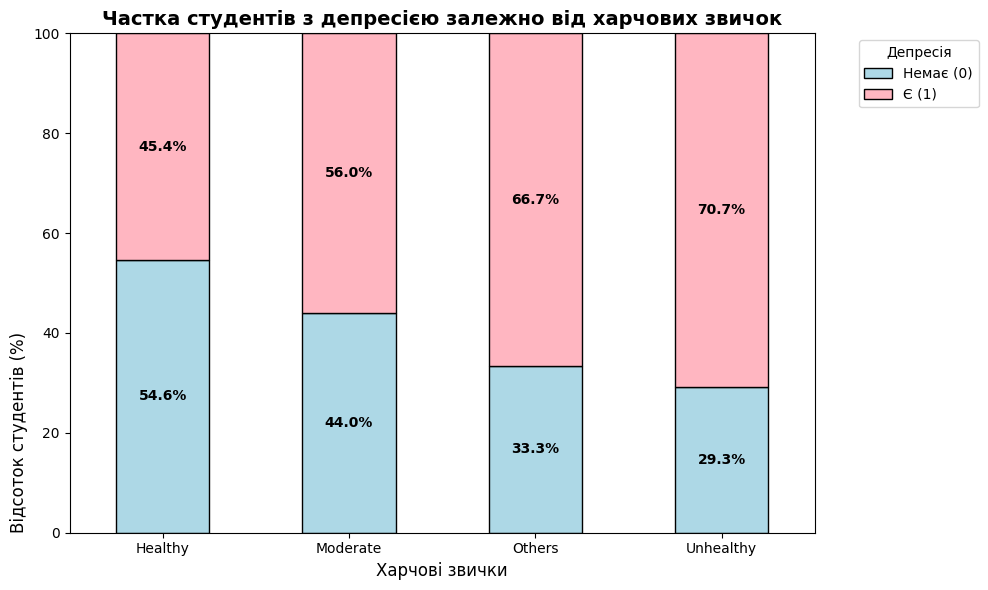

In [75]:
diet_dep = pd.crosstab(data['Dietary_Habits'], data['Depression'], normalize='index') * 100
my_colors = ['#ADD8E6', '#FFB6C1']
ax = diet_dep.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    color=my_colors,
    edgecolor='black')
ax.set_ylim(bottom=0, top=100)
plt.margins(y=0)
plt.title('Частка студентів з депресією залежно від харчових звичок', fontsize=14, fontweight='bold')
plt.xlabel('Харчові звички', fontsize=12)
plt.ylabel('Відсоток студентів (%)', fontsize=12, loc='bottom')
plt.xticks(rotation=0)
plt.legend(title='Депресія', labels=['Немає (0)', 'Є (1)'], bbox_to_anchor=(1.05, 1), loc='upper left')
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', label_type='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

Тип графіка:  згрупована стовпчаста діаграма.
Обґрунтування: Дозволяє порівняти співвідношення наявності/відсутності депресії всередині кожної категорії харчування. Мітки відсотків роблять графік самодостатнім і легким для швидкого аналізу.
Спостереження: Як не дивно, найбільша частка студентів БЕЗ депресії спостерігається серед тих, хто має помірні харчові звички. Серед тих, хто харчується здорово, відсоток депресії становить 45.4%.

висновки


Аналіз вибірки свідчить, що основну частку респондентів складають студенти віком 21-25 років (30.7%) та 26–30 років (28.1%). Це вказує на те, що більшість опитаних є дорослими, самостійними особами, які здатні свідомо піклуватися про власне здоров’я. Значна частина студентів має суттєвий дефіцит сну (спить менше 5 годин на добу), що безпосередньо свідчить про високе та виснажливе навантаження в університеті. У досліджуваному датасеті переважають особи з діагностованою депресією — 58.5%, тоді як частка студентів без цього захворювання становить 41.5%. Найбільша кількість респондентів навчається у містах Kalyan та Srinagar, найменша - у Kolkata. Середній бал (CGPA) більшості студентів є високим і концентрується в межах 9–10 балів.
Спостерігається чітка прямо пропорційна залежність. Чим вищий показник фінансового стресу, тим більша кількість студентів страждає на депресію. Зі зниженням фінансового тиску кількість хворих лінійно зменшується.
Академічний тиск наявний у більшості студентів із психічними порушеннями. Починаючи з рівня тиску 1, прослідковується стійке лінійне зростання частки осіб із депресією.
Студенти, які витрачають на навчання найменше часу (0-6 годин), зазвичай не мають депресії. Водночас пікове значення припадає на тих, хто вчиться по 10 годин на день - ця тривалість є найпоширенішою як серед здорових студентів, так і серед тих, хто має депресію.
У старших студентів депресія спостерігається частіше. При цьому найвищий рівень незадоволеності навчанням зафіксовано у віковій групі 40-50 років, тоді як для студентів віком до 35 років цей показник залишається майже незмінним.
У процесі аналізу було виявлено низку контрінтуїтивних фактів, які спростовують класичні припущення:
Ні наявність депресії, ні тривалість сну, ні кількість годин навчання не демонструють суттєвого впливу на оцінки. Академічний тиск також майже не впливає на успішність - середній бал стабільно тримається в діапазоні 6.5-9.5 (за винятком ізольованої групи з нульовим тиском).
Наявність психічних захворювань у родині жодним чином не впливає на ймовірність розвитку депресії у студентів з цієї вибірки.
Хоча очікувано велика частка людей із поганими харчовими звичками має депресію, статистичною аномалією є те, що серед студентів, які харчуються виключно здоровою їжею, показник захворюваності також критично високий - 45.4%.
Найбільшу аналітичну цінність продемонстрували стовпчасті діаграми (Bar plots) розподілу депресії залежно від фінансового та академічного стресу. Завдяки строгому форматуванню вони наочно підсвітили прямо пропорційні та лінійні тренди. Крім того, високоінформативними виявилися діаграми розсіяння (Scatter plots) для аналізу впливу часу навчання та сну на CGPA. Саме вони дозволили візуально підтвердити відсутність кореляції та показати щільне, рівномірне скупчення оцінок у межах 6.5-9.5 балів.
Ідеї для подальшого аналізу
Варто перевірити гіпотезу, чи не є здорове харчування фактором, що підвищує фінансовий стрес студента, що, у свою чергу, призводить до депресії.
Оскільки ця категорія студентів випадає із загального діапазону оцінок 6.5-9.5, необхідно дослідити їхні інші характеристики (вік, місто, години навчання), щоб зрозуміти причину цієї аномалії.
Враховуючи, що базові фактори (сон, години навчання) слабко корелюють з успішністю або депресією поодинці, доцільно застосувати алгоритми машинного навчання для виявлення складних нелінійних залежностей між змінними.
